In [5]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df = gpd.read_parquet('../data/processed/master_eda_v0_1.parquet')
print(df.shape)
print(df.crs.to_epsg())

(2822, 45)
32643


In [6]:
df.dtypes

candidate_id                                     int64
x                                              float64
y                                              float64
lon                                            float64
lat                                            float64
geometry                                      geometry
cafes_500m                                       int64
cafes_300m                                       int64
cafes_1000m                                      int64
bus_stops_500m                                   int64
residential_buildings_500m                       int64
houses_500m                                      int64
apartments_500m                                  int64
residential_unknown_500m                         int64
office_polygons_500m                             int64
offices_pois_500m                                int64
universities_500m                                int64
colleges_500m                                    int64
schools_50

In [7]:
df.isnull().sum()

candidate_id                                     0
x                                                0
y                                                0
lon                                              0
lat                                              0
geometry                                         0
cafes_500m                                       0
cafes_300m                                       0
cafes_1000m                                      0
bus_stops_500m                                   0
residential_buildings_500m                       0
houses_500m                                      0
apartments_500m                                  0
residential_unknown_500m                         0
office_polygons_500m                             0
offices_pois_500m                                0
universities_500m                                0
colleges_500m                                    0
schools_500m                                     0
shops_500m                     

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df['candidate_id'].nunique()

2822

In [11]:
df.describe()

,candidate_id,x,y,lon,lat,cafes_500m,cafes_300m,cafes_1000m,bus_stops_500m,residential_buildings_500m,...,district_housing_investment_mln_kzt,district_population_2026,district_avg_salary_kzt,district_active_sme_2026,district_sme_per_1000_residents,district_housing_m2_per_1000_residents,district_housing_investment_per_capita_kzt,dgis_coffee_sample_500m,dgis_coffee_reviews_sample_500m,dgis_coffee_rating_mean_sample_500m
count,2822.000000,2822.000000,2.822000e+03,2822.000000,2822.000000,2822.000000,2822.000000,2822.000000,2822.000000,2822.000000,...,2822.000000,2822.000000,2822.000000,2822.000000,2822.000000,2822.000000,2822.000000,2822.000000,2790.000000,757.000000
mean,1410.500000,657836.460587,4.786541e+06,76.943183,43.215121,0.813962,0.282424,3.223600,2.181786,69.811481,...,64404.204111,296695.889794,623717.322466,45790.089298,155.591217,959.801177,214919.109537,1.376329,432.668459,4.620632
std,814.785555,7082.709465,9.657894e+03,0.086404,0.087350,3.001673,1.165787,10.091989,3.468793,140.156397,...,25693.456974,63849.088420,143711.286842,11659.795791,30.457867,321.406502,55356.773364,4.026249,1788.749629,0.631228
min,0.000000,641765.588865,4.766898e+06,76.747990,43.035912,0.000000,0.000000,0.000000,0.000000,0.000000,...,5674.000000,199035.000000,419917.000000,28469.000000,104.901538,50.811231,15648.226544,0.000000,0.000000,1.000000
25%,705.250000,652265.588865,4.779398e+06,76.874385,43.149419,0.000000,0.000000,0.000000,0.000000,0.000000,...,46462.000000,257104.000000,461788.000000,34182.000000,129.548837,759.926646,180712.863277,0.000000,0.000000,4.640000
50%,1410.500000,658265.588865,4.785898e+06,76.949170,43.210961,0.000000,0.000000,0.000000,0.000000,1.000000,...,48668.000000,257104.000000,716798.000000,45037.000000,175.170359,878.691113,220642.438953,0.000000,0.000000,4.800000
75%,2115.750000,663265.588865,4.794898e+06,77.007061,43.290246,0.000000,0.000000,2.000000,4.000000,68.000000,...,78539.000000,355956.000000,769186.000000,53627.000000,175.170359,1007.309025,249122.590973,1.000000,5.000000,4.900000
max,2821.000000,675265.588865,4.807398e+06,77.162704,43.402232,42.000000,19.000000,116.000000,24.000000,885.000000,...,113365.000000,413952.000000,769186.000000,65143.000000,217.160925,1532.677702,283008.992720,36.000000,25277.000000,5.000000


In [12]:
cols = [
    "district",
    "district_Students_to_population",
    "district_Population_est",
    "district_Schools_capacity"
]

district_check = (
    df[cols]
    .drop_duplicates(subset="district")
    .sort_values("district")
)

display(district_check)

,district,district_Students_to_population,district_Population_est,district_Schools_capacity
0,Алатауский,283,182493,51706
664,Алмалинский,166,206574,34394
227,Ауэзовский,248,216162,53708
652,Бостандыкский,105,362150,38043
810,Жетысуский,249,114473,28551
1056,Медеуский,177,172300,30419
21,Наурызбайский,116,164413,19066
1224,Турксибский,239,162297,38759


In [13]:
district_check = district_check.copy()

district_check["calculated"] = (
    district_check["district_Schools_capacity"]
    / district_check["district_Population_est"]
    * 1000
).round().astype(int)

district_check["matches"] = (
    district_check["calculated"]
    == district_check["district_Students_to_population"]
)

display(district_check)

,district,district_Students_to_population,district_Population_est,district_Schools_capacity,calculated,matches
0,Алатауский,283,182493,51706,283,True
664,Алмалинский,166,206574,34394,166,True
227,Ауэзовский,248,216162,53708,248,True
652,Бостандыкский,105,362150,38043,105,True
810,Жетысуский,249,114473,28551,249,True
1056,Медеуский,177,172300,30419,177,True
21,Наурызбайский,116,164413,19066,116,True
1224,Турксибский,239,162297,38759,239,True


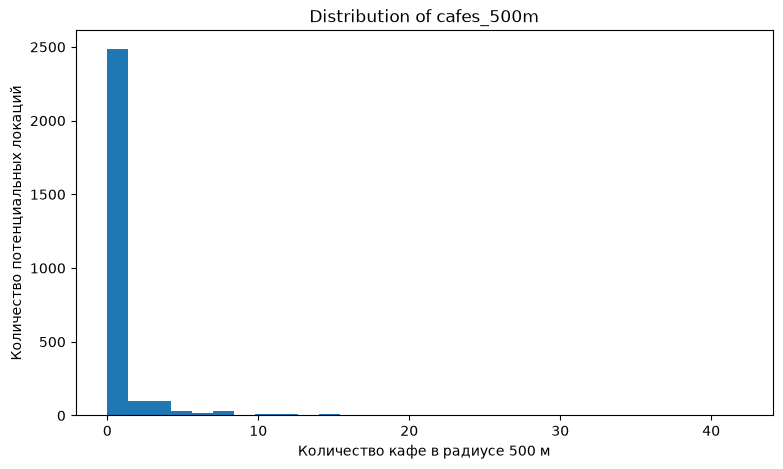

In [14]:
import matplotlib.pyplot as plt

feature = df["cafes_500m"]

plt.figure(figsize=(9, 5))
plt.hist(feature, bins=30)
plt.xlabel("Количество кафе в радиусе 500 м")
plt.ylabel("Количество потенциальных локаций")
plt.title("Distribution of cafes_500m")
plt.show()

In [27]:
print(f'Сколько кандидатных точек с 0 кофейнями рядом с собой: {(df['cafes_500m'] == 0).sum()}')
print(f'Процент от всех 2822 точек: {(df['cafes_500m'] == 0).sum()/((df.shape)[0])}')
print(f'Сколько точек имеют более 10 кафе в радиусе 500 метров: {(df['cafes_500m'] > 10).sum()}')

Сколько кандидатных точек с 0 кофейнями рядом с собой: 2268
Процент от всех 2822 точек: 0.8036853295535081
Сколько точек имеют более 10 кафе в радиусе 500 метров: 53


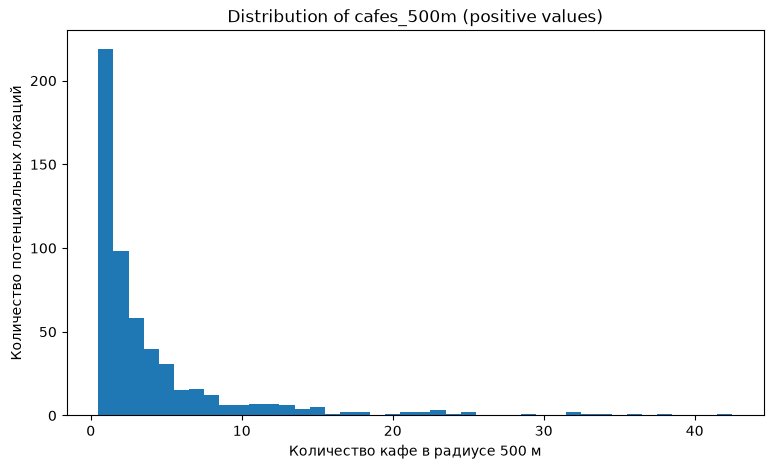

In [29]:
import numpy as np

cafes_positive = df.loc[
    df["cafes_500m"] > 0,
    "cafes_500m"
]

plt.figure(figsize=(9, 5))

plt.hist(
    cafes_positive,
    bins=np.arange(0.5, cafes_positive.max() + 1.5, 1)
)

plt.xlabel("Количество кафе в радиусе 500 м")
plt.ylabel("Количество потенциальных локаций")
plt.title("Distribution of cafes_500m (positive values)")
plt.show()

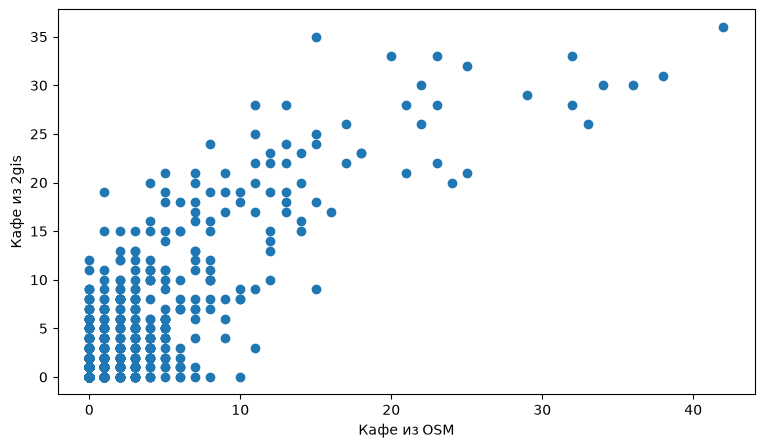

In [31]:
plt.figure(figsize=(9, 5))

cafes_osm_500 = df['cafes_500m']
dgis_coffee_sample_500m = df['dgis_coffee_sample_500m']

plt.scatter(cafes_osm_500, dgis_coffee_sample_500m)

plt.xlabel('Кафе из OSM')
plt.ylabel('Кафе из 2gis')

plt.show()

In [33]:
df[['cafes_500m', 'dgis_coffee_sample_500m']].corr()

,cafes_500m,dgis_coffee_sample_500m
cafes_500m,1.000000,0.849542
dgis_coffee_sample_500m,0.849542,1.000000


In [34]:
df["coffee_count_diff"] = (
    df["dgis_coffee_sample_500m"] - df["cafes_500m"]
)

print(df["coffee_count_diff"].describe())

print("\nДоля точек с одинаковыми значениями:")
print((df["coffee_count_diff"] == 0).mean() * 100)

#найти 10 потенциальных локаций, где количество кафе по OSM и 2GIS различается сильнее всего.

display(
    df.reindex(
        df["coffee_count_diff"].abs().sort_values(ascending=False).index
    )[["candidate_id", "district", "cafes_500m",
       "dgis_coffee_sample_500m", "coffee_count_diff"]].head(10)
)

count    2822.000000
mean        0.562367
std         2.164825
min       -10.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        20.000000
Name: coffee_count_diff, dtype: float64

Доля точек с одинаковыми значениями:
71.11977321048902


,candidate_id,district,cafes_500m,dgis_coffee_sample_500m,coffee_count_diff
1216,1216,Алмалинский,15,35,20
1144,1144,Бостандыкский,1,19,18
961,961,Бостандыкский,11,28,17
1275,1275,Бостандыкский,5,21,16
1274,1274,Бостандыкский,8,24,16
1145,1145,Бостандыкский,4,20,16
895,895,Бостандыкский,13,28,15
1082,1082,Бостандыкский,7,21,14
804,804,Бостандыкский,5,19,14
754,754,Ауэзовский,1,15,14


In [35]:
both_zero = (
    (df["cafes_500m"] == 0) &
    (df["dgis_coffee_sample_500m"] == 0)
)

active = (
    (df["cafes_500m"] > 0) |
    (df["dgis_coffee_sample_500m"] > 0)
)

print("Both zero:", both_zero.sum())
print("Active locations:", active.sum())

print(
    "Agreement among active locations:",
    (df.loc[active, "coffee_count_diff"] == 0).mean() * 100
)

Both zero: 1913
Active locations: 909
Agreement among active locations: 10.34103410341034


In [36]:
features = [
    "cafes_500m",
    "dgis_coffee_sample_500m"
]

print("All locations:")
print(df[features].corr())

print("\nActive locations only:")
print(df.loc[active, features].corr())

All locations:
                         cafes_500m  dgis_coffee_sample_500m
cafes_500m                 1.000000                 0.849542
dgis_coffee_sample_500m    0.849542                 1.000000

Active locations only:
                         cafes_500m  dgis_coffee_sample_500m
cafes_500m                 1.000000                 0.819741
dgis_coffee_sample_500m    0.819741                 1.000000


OSM vs 2GIS: коэффициент корреляции Пирсона составляет 0,85 на всех кандидатах и 0,82 среди локаций, где хотя бы один источник обнаружил заведения. Несмотря на сильную положительную связь, точные значения совпадают лишь у 10,34% активных локаций. Это говорит о сходных пространственных закономерностях, но не доказывает совпадение объектов или полноту источников.

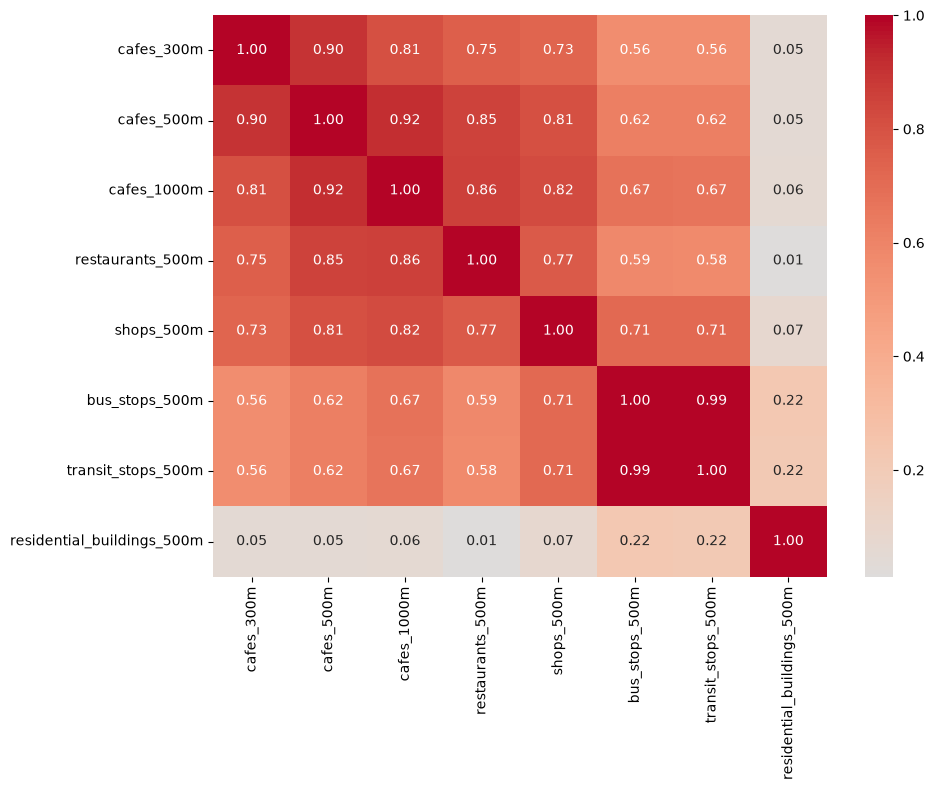

In [38]:
import seaborn as sns
features = [
    "cafes_300m",
    "cafes_500m",
    "cafes_1000m",
    "restaurants_500m",
    "shops_500m",
    "bus_stops_500m",
    "transit_stops_500m",
    "residential_buildings_500m"
]

corelation = df[features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corelation, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.tight_layout()
plt.show()

- Остановки транспорта: корреляция 0,993 между bus_stops_500m и transit_stops_500m указывает на почти полное линейное сходство. Перед K-Means стоит проверить, достаточно ли одного из признаков.
- Кафе: корреляции 0,90–0,92 между разными радиусами показывают сильную взаимосвязь плотности кафе.
- Жилая застройка: residential_buildings_500m имеет слабую линейную связь с коммерческими признаками. Этот показатель может содержать дополнительную информацию, но его полезность ещё нужно проверить.

In [39]:
diff = df["bus_stops_500m"] - df["transit_stops_500m"]

print("Совпадений:", (diff == 0).sum())
print("Доля совпадений:", (diff == 0).mean() * 100)
print("Максимальное расхождение:", diff.abs().max())
print(diff.value_counts().sort_index())

Совпадений: 2656
Доля совпадений: 94.11764705882352
Максимальное расхождение: 5
-5       2
-4       5
-3      14
-2      37
-1      75
 0    2656
 1      30
 2       2
 3       1
Name: count, dtype: int64


In [40]:
df["stops_diff"] = (
    df["bus_stops_500m"] - df["transit_stops_500m"]
)

display(
    df.loc[
        df["stops_diff"].abs() >= 3,
        [
            "candidate_id",
            "district",
            "bus_stops_500m",
            "transit_stops_500m",
            "stops_diff"
        ]
    ].sort_values("stops_diff")
)

,candidate_id,district,bus_stops_500m,transit_stops_500m,stops_diff
86,86,Наурызбайский,4,9,-5
1218,1218,Жетысуский,5,10,-5
23,23,Наурызбайский,2,6,-4
70,70,Алатауский,1,5,-4
131,131,Наурызбайский,0,4,-4
1284,1284,Жетысуский,3,7,-4
1283,1283,Жетысуский,9,13,-4
21,21,Наурызбайский,4,7,-3
1418,1418,Жетысуский,9,12,-3
1351,1351,Жетысуский,5,8,-3


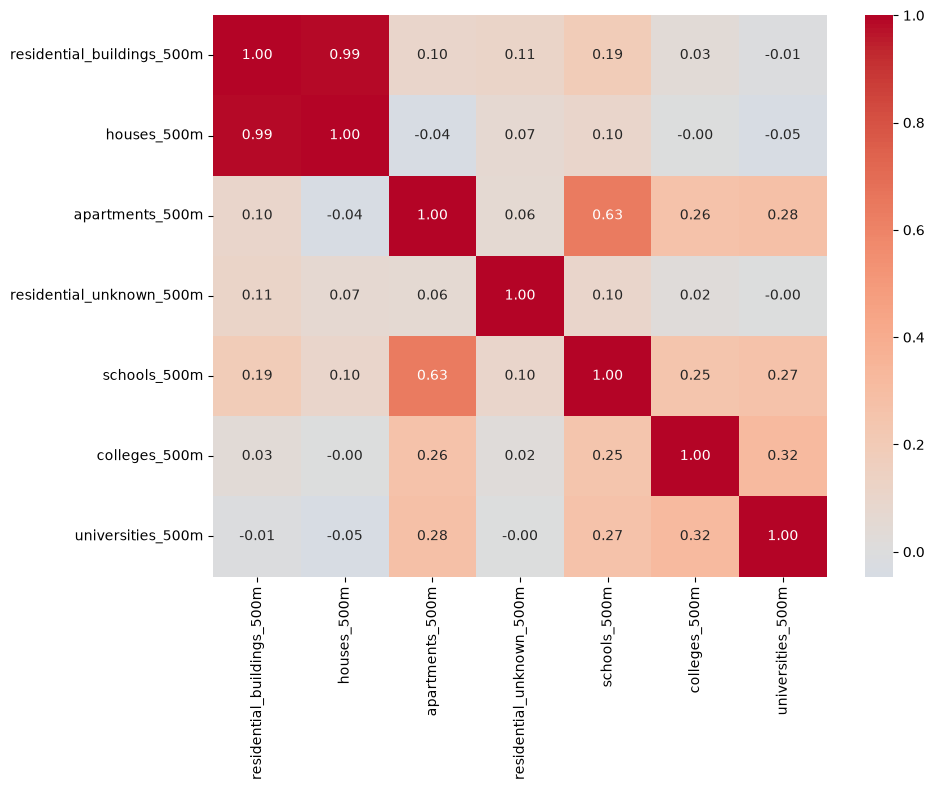

In [42]:
residential_features = [
    "residential_buildings_500m",
    "houses_500m",
    "apartments_500m",
    "residential_unknown_500m",
    "schools_500m",
    "colleges_500m",
    "universities_500m"
]

residential_corr = df[residential_features].corr()



plt.figure(figsize=(10, 8))
sns.heatmap(residential_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.tight_layout()
plt.show()

In [43]:
components_sum = (
    df["houses_500m"]
    + df["apartments_500m"]
    + df["residential_unknown_500m"]
)

difference = (
    df["residential_buildings_500m"] - components_sum
)

print("Полных совпадений:", (difference == 0).sum())
print("Доля совпадений:", (difference == 0).mean() * 100)
print("Максимальное расхождение:", difference.abs().max())

Полных совпадений: 2822
Доля совпадений: 100.0
Максимальное расхождение: 0


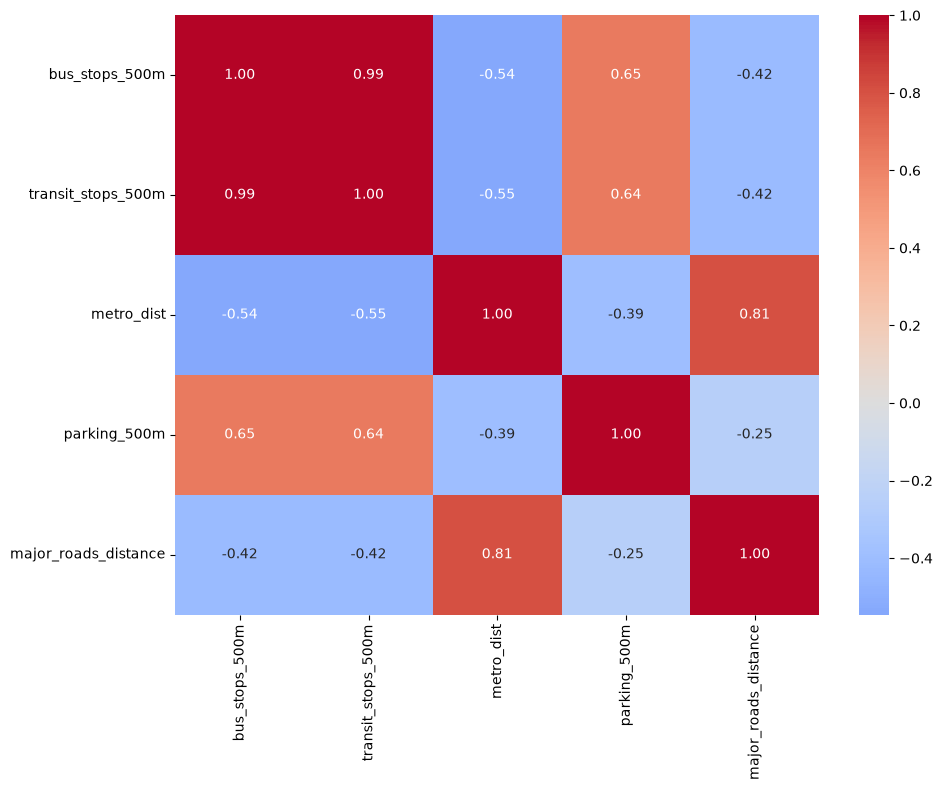

In [44]:
transport_features = [
    "bus_stops_500m",
    "transit_stops_500m",
    "metro_dist",
    "parking_500m",
    "major_roads_distance"
]

transport_corr = df[transport_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(transport_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.tight_layout()
plt.show()

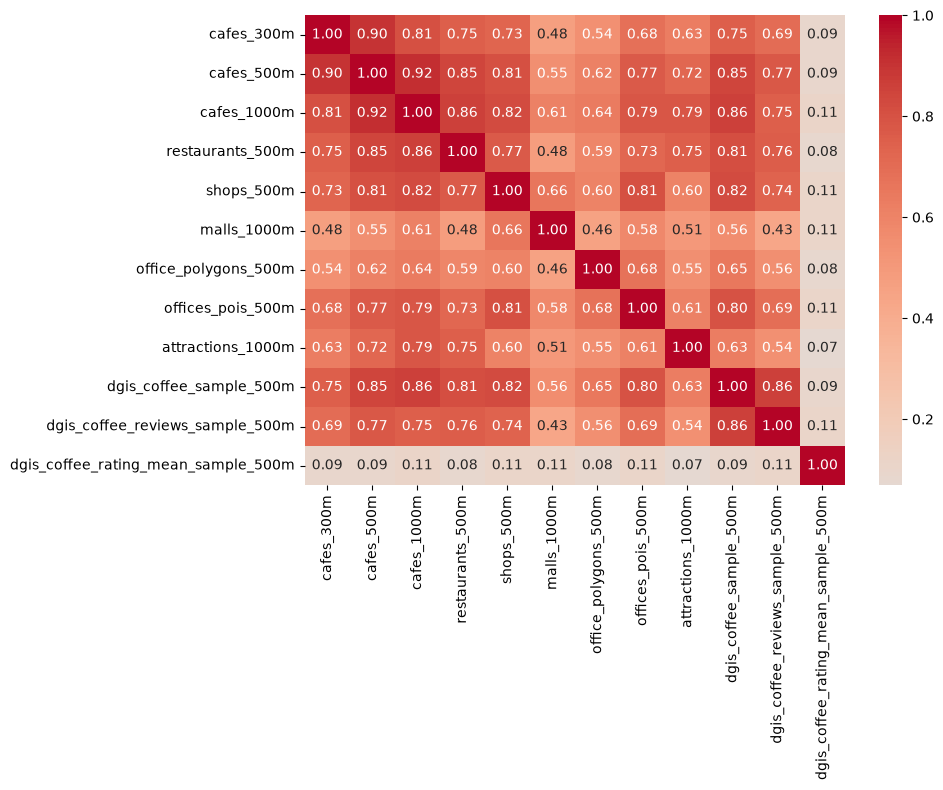

In [45]:
commercial_features = [
    "cafes_300m",
    "cafes_500m",
    "cafes_1000m",
    "restaurants_500m",
    "shops_500m",
    "malls_1000m",
    "office_polygons_500m",
    "offices_pois_500m",
    "attractions_1000m",
    "dgis_coffee_sample_500m",
    "dgis_coffee_reviews_sample_500m",
    "dgis_coffee_rating_mean_sample_500m"
]

commercial_corr = df[commercial_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(commercial_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.tight_layout()
plt.show()

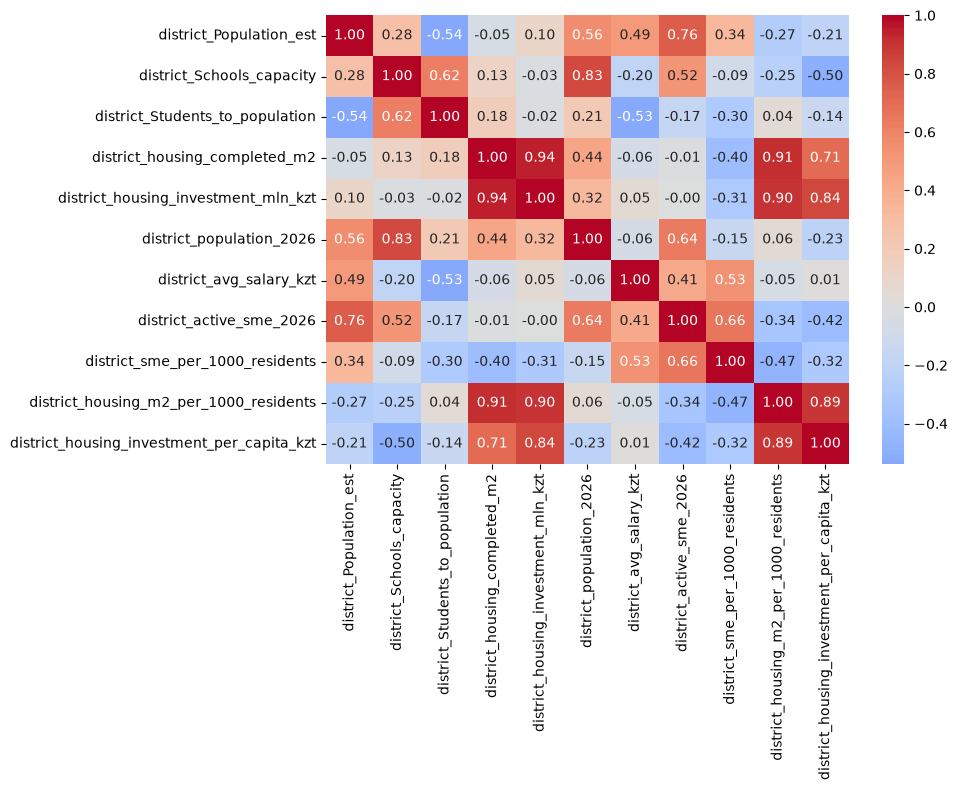

In [47]:
#оставляем только по одному примеру для однго района, нас интересуют корр между районами а не всеми точками
district_df = df.drop_duplicates(subset="district").copy()

#берем только те колонки которые начинаются с district и не является district_distance_m
district_features = [
    col for col in district_df.select_dtypes(include="number").columns
    if col.startswith("district_")
    and col != "district_distance_m"
]

district_corr = district_df[district_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(district_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.tight_layout()
plt.show()

# Spatial EDA

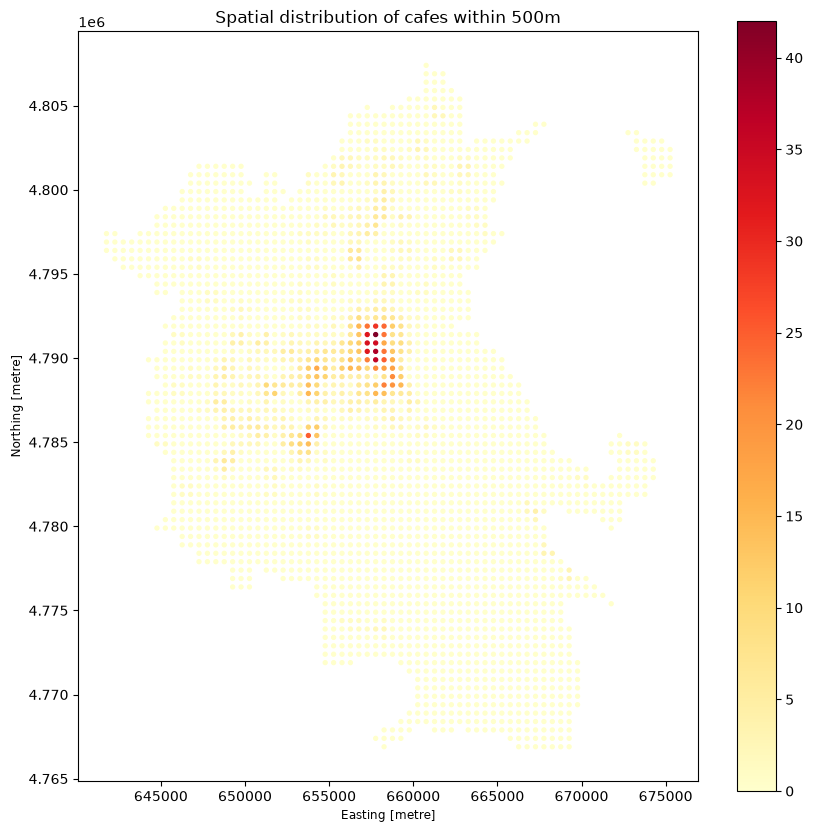

In [48]:
fig, ax = plt.subplots(figsize=(10, 10))

df.plot(
    column="cafes_500m",
    cmap="YlOrRd",
    markersize=8,
    legend=True,
    ax=ax
)

ax.set_title("Spatial distribution of cafes within 500m")
plt.show()

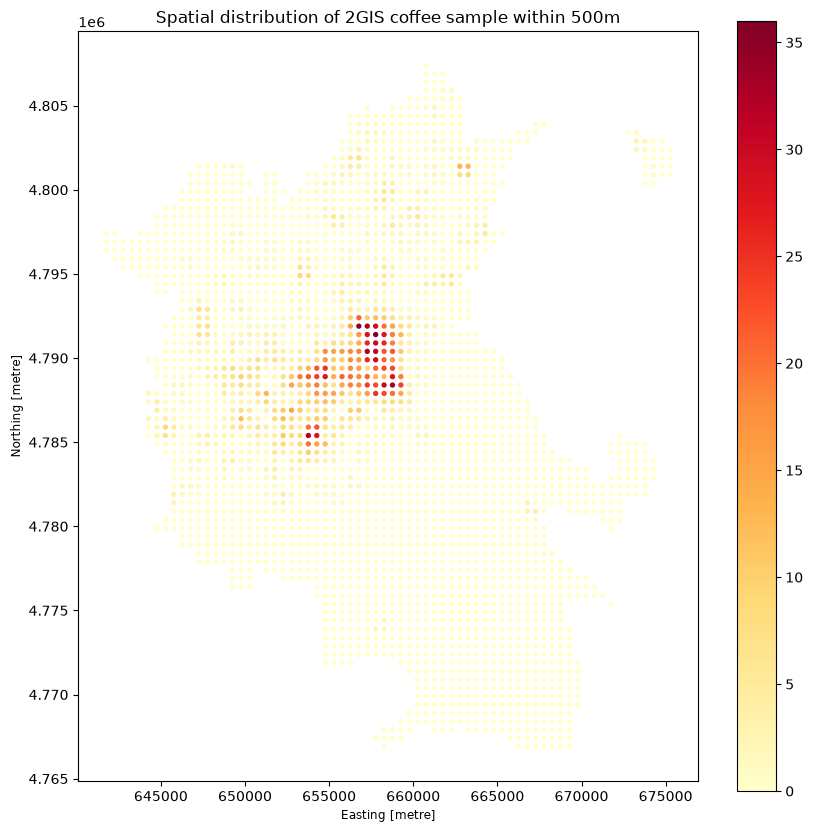

In [49]:
fig, ax = plt.subplots(figsize=(10, 10))

df.plot(
    column="dgis_coffee_sample_500m",
    cmap="YlOrRd",
    markersize=8,
    legend=True,
    ax=ax
)

ax.set_title("Spatial distribution of 2GIS coffee sample within 500m")
plt.show()